## 1. Import libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Load dataset


In [4]:
from google.colab import files

uploaded = files.upload()


Saving tripadvisor_review.csv to tripadvisor_review.csv


In [6]:
from google.colab import files

uploaded = files.upload()

Saving tripadvisor_review.csv to tripadvisor_review (1).csv


In [7]:
print(uploaded.keys())


dict_keys(['tripadvisor_review (1).csv'])


In [8]:
filename = list(uploaded.keys())[0]

tripadvisor_dataset = pd.read_csv(filename)

print('Dataset shape:', tripadvisor_dataset.shape)

tripadvisor_dataset.head()

Dataset shape: (980, 11)


,User ID,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10
0,User 1,0.93,1.8,2.29,0.62,0.80,2.42,3.19,2.79,1.82,2.42
1,User 2,1.02,2.2,2.66,0.64,1.42,3.18,3.21,2.63,1.86,2.32
2,User 3,1.22,0.8,0.54,0.53,0.24,1.54,3.18,2.80,1.31,2.50
3,User 4,0.45,1.8,0.29,0.57,0.46,1.52,3.18,2.96,1.57,2.86
4,User 5,0.51,1.2,1.18,0.57,1.54,2.02,3.18,2.78,1.18,2.54


## 3. Data cleaning


In [9]:
# 1. Missing values
missing_values = tripadvisor_dataset.isnull().sum()

print("Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0
      else "No missing values detected.")

# Fill missing numbers with the median
for col in tripadvisor_dataset.columns:
    if tripadvisor_dataset[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(tripadvisor_dataset[col]):
            tripadvisor_dataset[col] = tripadvisor_dataset[col].fillna(
                tripadvisor_dataset[col].median()
            )

# 2. Duplicates
duplicates_count = tripadvisor_dataset.duplicated().sum()

print("\nDuplicate rows found:", duplicates_count)

if duplicates_count > 0:
    tripadvisor_dataset = tripadvisor_dataset.drop_duplicates()

# Reset row numbers
tripadvisor_dataset = tripadvisor_dataset.reset_index(drop=True)

# Check
print("\nCleaned dataset shape:", tripadvisor_dataset.shape)

tripadvisor_dataset.head()

Missing values per column:
No missing values detected.

Duplicate rows found: 0

Cleaned dataset shape: (980, 11)


,User ID,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10
0,User 1,0.93,1.8,2.29,0.62,0.80,2.42,3.19,2.79,1.82,2.42
1,User 2,1.02,2.2,2.66,0.64,1.42,3.18,3.21,2.63,1.86,2.32
2,User 3,1.22,0.8,0.54,0.53,0.24,1.54,3.18,2.80,1.31,2.50
3,User 4,0.45,1.8,0.29,0.57,0.46,1.52,3.18,2.96,1.57,2.86
4,User 5,0.51,1.2,1.18,0.57,1.54,2.02,3.18,2.78,1.18,2.54


## 4. Select Features


In [10]:
# remove user ID bc it is not necessary for PCA
exclude_cols = ['User ID']

numeric_features = [
    c for c in tripadvisor_dataset.select_dtypes(include='number').columns
    if c not in exclude_cols
]

print('Numerical features used for PCA:', numeric_features)

Numerical features used for PCA: ['Category 1', 'Category 2', 'Category 3', 'Category 4', 'Category 5', 'Category 6', 'Category 7', 'Category 8', 'Category 9', 'Category 10']


## 5. Standardize the features


In [11]:
# Select the numerical data
x_raw = tripadvisor_dataset[numeric_features]

# Standardize data
scaler = StandardScaler()
x = scaler.fit_transform(x_raw)

x_scaled_df = pd.DataFrame(x, columns=numeric_features)

print('Shape:', x.shape)
print('All means ~0:', np.allclose(x.mean(axis=0), 0))
print('All stds ~1:', np.allclose(x.std(axis=0), 1))

# Show the first 5 rows
x_scaled_df.head()

Shape: (980, 10)
All means ~0: True
All stds ~1: True


,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10
0,0.112645,0.935887,1.619750,0.312960,-0.319608,1.070169,1.158657,-0.327872,0.687518,-1.180591
1,0.388088,1.772644,2.089171,0.384494,1.098486,2.479500,3.716053,-1.492056,0.797274,-1.491908
2,1.000186,-1.156005,-0.600487,-0.008942,-1.600466,-0.561689,-0.120041,-0.255111,-0.711877,-0.931537
3,-1.356389,0.935887,-0.917663,0.134126,-1.097272,-0.598777,-0.120041,0.909073,0.001540,0.189205
4,-1.172760,-0.319248,0.211486,0.134126,1.372955,0.328415,-0.120041,-0.400634,-1.068585,-0.807010


## 6. Apply PCA


In [12]:
# Reduce the number of features to 2 components
n_features = x.shape[1]

pca = PCA(n_components=2)
principal_components = pca.fit_transform(x)

print(f'Reduced {n_features} features -> 2 components')
print('PCA output shape:', principal_components.shape)

# Create a dataframe with PC1 and PC2
pca_df = pd.DataFrame(
    principal_components,
    columns=['PC1', 'PC2']
)

print('\nFirst 5 rows of PCA result:')
print(pca_df.head())

Reduced 10 features -> 2 components
PCA output shape: (980, 2)

First 5 rows of PCA result:
        PC1       PC2
0  2.407573 -0.073039
1  5.311237 -0.022500
2 -0.807839 -1.776951
3 -1.065346  0.856401
4  0.987246 -0.076777


## ## 7. Explained variance ratio

In [13]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('PC1: {:.1%}'.format(pc1_var))
print('PC2: {:.1%}'.format(pc2_var))
print('Total: {:.1%}'.format(pc1_var + pc2_var))


Explained variance per principal component:
PC1: 29.8%
PC2: 12.6%
Total: 42.4%


## 8. What PC1 and PC2 are made of (loadings)


In [14]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=numeric_features,
    columns=['PC1', 'PC2']
)

print(loadings.round(3))

# Find the top 3 categories for each component
for pc in ['PC1', 'PC2']:
    print(f'\n{pc} is driven mostly by:')
    print(
        loadings[pc].abs()
        .sort_values(ascending=False)
        .head(3)
        .round(3)
    )

               PC1    PC2
Category 1  -0.015 -0.319
Category 2   0.130  0.297
Category 3   0.429 -0.283
Category 4   0.229 -0.019
Category 5   0.322  0.346
Category 6   0.417  0.249
Category 7   0.496 -0.143
Category 8  -0.105  0.420
Category 9   0.040  0.586
Category 10 -0.459  0.090

PC1 is driven mostly by:
Category 7     0.496
Category 10    0.459
Category 3     0.429
Name: PC1, dtype: float64

PC2 is driven mostly by:
Category 9    0.586
Category 8    0.420
Category 5    0.346
Name: PC2, dtype: float64


## 9. Visualize the PCA result


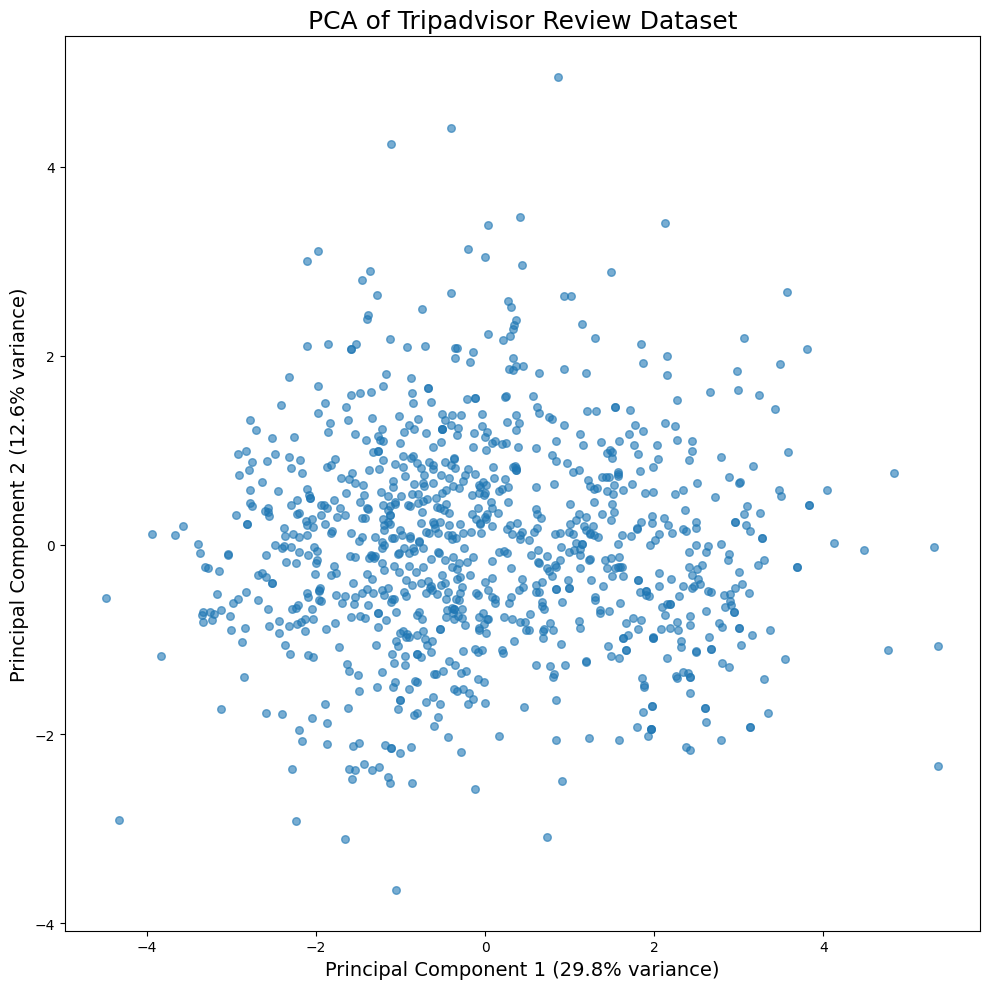

Plot saved as pca_tripadvisor.png


In [15]:
# Create a scatter plot(PC1 and PC2)
plt.figure(figsize=(10, 10))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=30,
    alpha=0.6
)

plt.xlabel(
    'Principal Component 1 ({:.1%} variance)'.format(pc1_var),
    fontsize=14
)

plt.ylabel(
    'Principal Component 2 ({:.1%} variance)'.format(pc2_var),
    fontsize=14
)

plt.title(
    'PCA of Tripadvisor Review Dataset',
    fontsize=18
)

plt.tight_layout()

plt.savefig('pca_tripadvisor.png', dpi=150)

plt.show()

print('Plot saved as pca_tripadvisor.png')

##Summary
| Component | Variance Explained | Role |
| :--- | :--- | :--- |
| **PC1** | **~29.8%** | Mainly influenced by category 7, 10, and 3 |
| **PC2** | **~12.6%** | Mainly influenced by category 5, 8, and 9 |
| **Combined** | **~42.4%** | Total variance showed by two components |

## According to the plot...
- Most of the points are gathered near the center
- many users show similar patterns
- there are no completely clear groups.

## Key takeaways
- PCA made 10 categoreis to 2 components by reducing unnecessary things.
- PC1 is mainly about categories 3, 7, and 10 .
- PC2 is mainly about categories 5, 8, and 9.
- the two components explain 42.4% of data.
